In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display, Markdown
from scipy import ndimage as ndi
from scipy.spatial import cKDTree

import hashlib
import json
import re
import zipfile
import xml.etree.ElementTree as ET

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', 20)
RANDOM_STATE = 42

Matplotlib is building the font cache; this may take a moment.


<h1 style="font-weight: normal;">Визуализация данных</h1>
Для начала давайте посмотрим, с какими данными мы работаем.

Для задачи сегментации и классификации геометрических состояний металлизации
я использую IC SEM M2. Это электронно-микроскопические изображения второго
слоя металлизации интегральной схемы и соответствующая разметка материала.

Сначала нужно понять, как устроены изображения и маски, какие классы можно
сформировать на их основе и какие свойства данных необходимо учесть при
построении модели. Один объект рабочего набора — локальный фрагмент SEM
и его бинарная маска.

Практический интерес для микроэлектроники связан с восстановлением геометрии
проводников и распознаванием соединений между участками металлизации.

<h2 style="font-weight: normal;">Описание датасета</h2>
Набор опубликован авторами работы *Towards Unsupervised SEM Image Segmentation
for IC Layout Extraction*. Он содержит изображения слоёв M1 и M2 одной
интегральной схемы. Для анализа выбираю M2, поскольку для этого слоя
доступны SVG-разметки дорожек и межслойных контактов.

| Характеристика | Значение |
|---|---|
| Объект съёмки | Логическая область одной коммерческой интегральной схемы |
| Используемый слой | Второй слой металлизации, M2 |
| Исходный объём M2 | 321 SEM-изображение и 321 SVG-разметка |
| Размер исходного кадра | 4096 × 3536 пикселей |
| Масштаб по описанию авторов | 14,65 нм на пиксель |
| Условия съёмки | 15 кэВ, детектор обратно рассеянных электронов, 3 мкс на пиксель |
| Перекрытие соседних кадров | Около 10% |
| Разметка | Автоматическое выделение дорожек и контактов с ручной проверкой и исправлением |
| Лицензия | CC BY 4.0 |

В README авторы указывают технологический узел 128 нм. Масштаб
14,65 нм/пиксель характеризует дискретизацию изображения; его не следует
отождествлять с отдельно измеренным разрешением микроскопа.
Авторы также отмечают возможные повторные контуры контактов и неполноту
разметки дорожек, проходящих через несколько кадров.

Источники: [набор данных](https://doi.org/10.17617/3.HY5SYN),
[статья](https://doi.org/10.1145/3605769.3624000),
[авторский репозиторий](https://github.com/emsec/unsupervised-ic-sem-segmentation).

In [2]:
# Пути работают при запуске из корня репозитория, папки gipoteza или папки EDA.
REPO_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'gipoteza/shared_data/ic_sem_m2/labels.zip').exists()
)
DATA_DIR = REPO_ROOT / 'gipoteza/sem_architecture_pilot_20261102'
SHARED_DIR = REPO_ROOT / 'gipoteza/shared_data/ic_sem_m2'
OLD_SOURCES = REPO_ROOT / 'gipoteza/sem_confirmation_20261028/sources'

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

with zipfile.ZipFile(SHARED_DIR / 'labels.zip') as archive:
    svg_members = sorted(n for n in archive.namelist() if n.endswith('.svg'))
    author_readme = archive.read('dataset/README').decode('utf-8')

listing = json.loads((SHARED_DIR / 'sem_zip_listing.json').read_text())
m2_members = [r for r in listing
              if re.fullmatch(r'dataset/sems/m2/sem\d+\.png', r['name'])]

print(f'Исходных SEM-кадров M2 в индексе авторского архива: {len(m2_members)}')
print(f'Исходных SVG-разметок M2 в локальном архиве:      {len(svg_members)}')
print('Полный архив SEM не загружается: для EDA достаточно сохранённых данных.')

Исходных SEM-кадров M2 в индексе авторского архива: 321
Исходных SVG-разметок M2 в локальном архиве:      321
Полный архив SEM не загружается: для EDA достаточно сохранённых данных.


<h2 style="font-weight: normal;">Загрузка рабочего набора</h2>
Для первичного анализа использую рабочую подвыборку: 15 105 фрагментов
из 16 исходных кадров. Такой объём позволяет посмотреть на изображения,
распределения и геометрию разметки без загрузки всего архива SEM.
Эти фрагменты относятся к одной микросхеме, поэтому не являются наблюдениями
15 105 независимых изделий.

В архиве хранятся изображения `X`, бинарные маски `Y`, геометрический класс
`label`, назначение примера `role` и номер кадра `frame`. В таблице описания
также указаны координаты фрагментов и ключи для проверки повторов.
Загружу данные и посмотрю на их размер, поля и типы.

In [3]:
with np.load(DATA_DIR / 'DATA.npz', allow_pickle=False) as archive:
    arrays = {name: archive[name].copy() for name in archive.files}

manifest = json.loads((DATA_DIR / 'DATA_MANIFEST.json').read_text())
assert sha256(DATA_DIR / 'DATA.npz') == manifest['DATA_sha256']

X = arrays['X'][:, 0]   # SEM, [N, 12, 12], яркость в диапазоне [0, 1]
Y = arrays['Y'][:, 0]   # маска металла, [N, 12, 12], значения 0/1
df = pd.DataFrame(manifest['records'])
df['image'] = df['frame'].map(lambda frame: f'sem{frame:04d}.png')
df['split'] = df['role'].replace({'dense': 'train', 'weak': 'train'})

print('Размер рабочего датасета')
print(f'Объектов:         {len(df):,}')
print(f'Исходных кадров:  {df["frame"].nunique()}')
print(f'Размер фрагмента: {X.shape[1]} × {X.shape[2]}')
print(f'Полей в таблице:  {len(df.columns)}')
print(f'\nКолонки: {df.columns.tolist()}')
print(f'\nТипы данных:\n{df.dtypes}')
display(df[['image', 'frame', 'x', 'y', 'label', 'role', 'split']].head())

display(pd.DataFrame([
    {'Массив': name, 'Форма': str(value.shape), 'Тип': str(value.dtype),
     'Объём, МиБ': round(value.nbytes / 2**20, 3)}
    for name, value in arrays.items()
]))

Размер рабочего датасета
Объектов:         15,105
Исходных кадров:  16
Размер фрагмента: 12 × 12
Полей в таблице:  9

Колонки: ['frame', 'y', 'x', 'canonical_D4', 'raw_D4_sha256', 'label', 'role', 'image', 'split']

Типы данных:
frame            int64
y                int64
x                int64
canonical_D4       str
raw_D4_sha256      str
label            int64
role               str
image              str
split              str
dtype: object


,image,frame,x,y,label,role,split
0,sem0003.png,3,896,1040,0,dense,train
1,sem0004.png,4,1592,1064,0,dense,train
2,sem0005.png,5,2000,1448,0,dense,train
3,sem0000.png,0,3176,536,0,dense,train
4,sem0005.png,5,2936,2264,0,dense,train


,Массив,Форма,Тип,"Объём, МиБ"
0,X,"(15105, 1, 12, 12)",float32,8.297
1,Y,"(15105, 1, 12, 12)",uint8,2.074
2,label,"(15105,)",int64,0.115
3,role,"(15105,)",<U5,0.288
4,frame,"(15105,)",int64,0.115


`x` и `y` задают левый верхний угол фрагмента в исходном кадре.
Поля таблицы описывают происхождение и назначение примера, а само изображение
содержит 144 значения яркости. Маска содержит столько же пикселей.

Перед визуальным анализом проверю пропуски, допустимые значения,
соответствие записей массивам и наличие исходных файлов.

In [4]:
def source_path(frame, mask=False):
    folder = OLD_SOURCES if int(frame) < 8 else DATA_DIR / 'sources'
    return folder / (f'label{int(frame):04d}.svg' if mask else f'sem{int(frame):04d}.png')

missing_images = [int(f) for f in sorted(df['frame'].unique())
                  if not source_path(f).is_file()]
missing_masks = [int(f) for f in sorted(df['frame'].unique())
                 if not source_path(f, mask=True).is_file()]

print(f'Пропуски:\n{df.isnull().sum()}')
print(f'\nПовторы одного положения (frame, x, y): {df.duplicated(["frame", "x", "y"]).sum()}')
print(f'Отсутствующих исходных PNG для этих 16 кадров: {len(missing_images)}')
print(f'Отсутствующих SVG для этих 16 кадров:          {len(missing_masks)}')
print(f'Неизвестных классов: {(~df["label"].isin(range(9))).sum()}')
print(f'Неизвестных назначений: {(~df["role"].isin(["dense", "weak", "val", "test"])).sum()}')
print(f'Неконечных значений SEM: {(~np.isfinite(X)).sum()}')
print(f'Диапазон яркости SEM: [{X.min():.6f}; {X.max():.6f}]')
print(f'Значения маски: {np.unique(Y)}')

assert len(df) == len(X) == len(Y)
assert np.isfinite(X).all() and 0 <= X.min() <= X.max() <= 1
assert set(np.unique(Y)) <= {0, 1}
assert not missing_images and not missing_masks
assert not df[['frame', 'x', 'y', 'label', 'role']].isnull().any().any()
for name in ['frame', 'label', 'role']:
    assert np.array_equal(df[name].to_numpy(), arrays[name])

Пропуски:
frame            0
y                0
x                0
canonical_D4     0
raw_D4_sha256    0
label            0
role             0
image            0
split            0
dtype: int64

Повторы одного положения (frame, x, y): 0
Отсутствующих исходных PNG для этих 16 кадров: 0
Отсутствующих SVG для этих 16 кадров:          0
Неизвестных классов: 0
Неизвестных назначений: 0
Неконечных значений SEM: 0
Диапазон яркости SEM: [0.087745; 1.000000]
Значения маски: [0 1]


Проверка не выявила пропусков и несогласованных записей. Яркости SEM лежат
в ожидаемом диапазоне, а маски содержат только 0 и 1. Для всех рассматриваемых
кадров доступны исходное изображение и SVG-разметка.

Одно имя PNG встречается у нескольких объектов, поскольку из кадра вырезается
много участков. Поэтому дубликаты нужно искать по координатам и содержимому,
а не только по имени исходного файла.

<h2 style="font-weight: normal;">Исходные изображения и разметка</h2>
Теперь посмотрю на полный SEM-кадр и соответствующую разметку.
SVG хранит контуры дорожек и контактов. Для задачи сегментации объединю
их в бинарную маску: 1 — металл, 0 — фон.

Такая маска описывает материал металлизации. Она не является отдельной
экспертной разметкой производственных дефектов.

,Кадр,Ширина,Высота,Режим,"Размер PNG, МиБ"
0,0,4096,3536,L,9.20
1,1,4096,3536,L,9.21
2,2,4096,3536,L,9.15
3,3,4096,3536,L,9.17
4,4,4096,3536,L,9.17
5,5,4096,3536,L,9.17
6,6,4096,3536,L,9.18
7,7,4096,3536,L,9.19
8,41,4096,3536,L,9.21
9,47,4096,3536,L,9.19


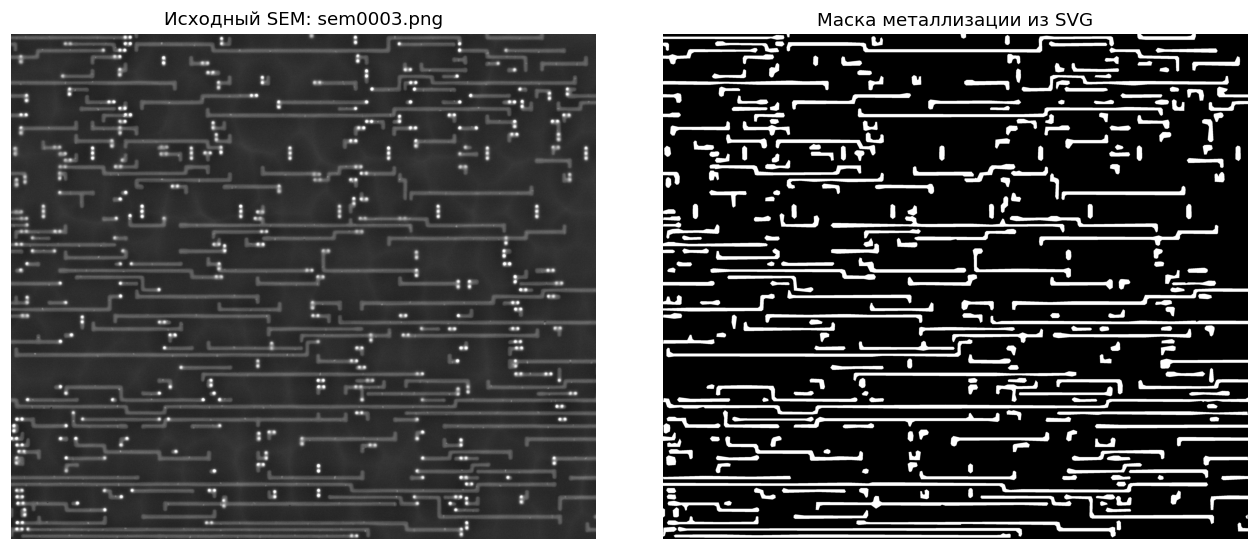

In [5]:
def read_native_pair(frame):
    image = np.asarray(Image.open(source_path(frame)).convert('L'))
    canvas = Image.new('L', (image.shape[1], image.shape[0]), 0)
    draw = ImageDraw.Draw(canvas)
    tree = ET.parse(source_path(frame, mask=True))
    for element in tree.iter():
        assert 'transform' not in element.attrib
        if element.tag.endswith('}path'):
            path = element.attrib['d']
            assert set(re.findall('[A-Za-z]', path)) <= set('MLZz')
            points = [(int(x), int(y))
                      for x, y in re.findall(r'[ML](\d+),(\d+) ', path)]
            assert len(points) >= 3
            draw.polygon(points, fill=1)
    return image, np.asarray(canvas, dtype=np.uint8)

frame_info = []
for frame in sorted(df['frame'].unique()):
    with Image.open(source_path(frame)) as image:
        frame_info.append({'Кадр': int(frame), 'Ширина': image.width,
                           'Высота': image.height, 'Режим': image.mode,
                           'Размер PNG, МиБ': source_path(frame).stat().st_size / 2**20})
display(pd.DataFrame(frame_info).round(2))

example_row = df[df['role'] == 'dense'].iloc[0]
native_image, native_mask = read_native_pair(int(example_row['frame']))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(native_image, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f'Исходный SEM: {example_row["image"]}')
axes[1].imshow(native_mask, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Маска металлизации из SVG')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

На SEM видны проводники, изменения яркости и шум. В бинарной маске
геометрия представлена без полутонов. Все 16 рассматриваемых кадров имеют
одинаковый размер и один канал яркости.

<h2 style="font-weight: normal;">Подготовка локальных фрагментов</h2>
Для анализа локальной геометрии использую следующую схему подготовки:

1. Исключаю полосу шириной 512 исходных пикселей по краям кадра.
2. Усредняю яркость в блоках $4\times4$. Маску уменьшаю по большинству:
   пиксель относится к металлу, если его доля в блоке не меньше 0,5.
3. Рассматриваю участки $12\times12$ с шагом 6 в уменьшенном изображении.
4. Исключаю однородные маски и точные повторы изображения или геометрии
   с учётом поворотов и отражений.
5. Формирую обучающую часть с фиксированным числом примеров каждого класса.

Один участок соответствует $48\times48$ исходным пикселям, или примерно
$703\times703$ нм по авторскому масштабу. Шаг между участками составляет
24 исходных пикселя. Далее проверю, как уменьшение выглядит на конкретном
примере и соответствует ли готовый фрагмент исходной разметке.

Кадр 3, координаты x=896, y=1040
Максимальное отличие восстановленного SEM: 0.00e+00
Маска после уменьшения совпадает: True


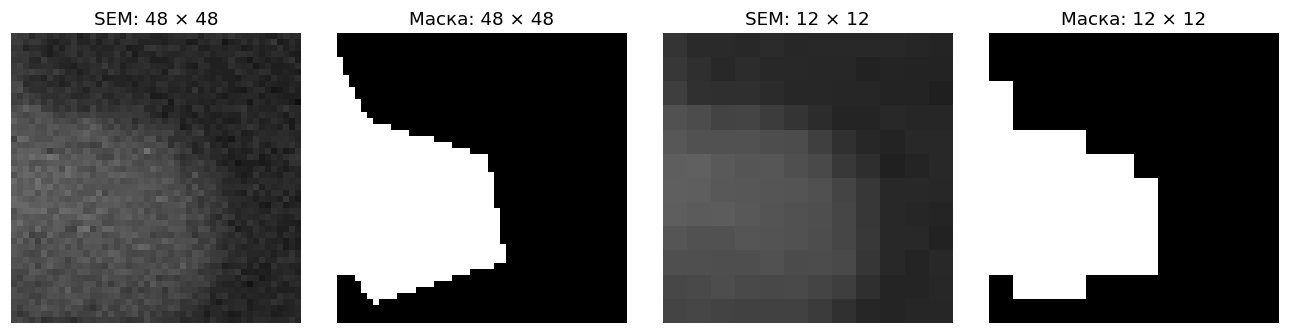

In [6]:
row_id = int(example_row.name)
x0, y0 = int(example_row['x']), int(example_row['y'])
crop = native_image[y0:y0 + 48, x0:x0 + 48]
crop_mask = native_mask[y0:y0 + 48, x0:x0 + 48]
reduced = crop.reshape(12, 4, 12, 4).sum((1, 3)).astype(np.float32) / (16 * 255)
reduced_mask = (crop_mask.reshape(12, 4, 12, 4).mean((1, 3)) >= 0.5).astype(np.uint8)

print(f'Кадр {example_row["frame"]}, координаты x={x0}, y={y0}')
print(f'Максимальное отличие восстановленного SEM: {np.abs(reduced - X[row_id]).max():.2e}')
print(f'Маска после уменьшения совпадает: {np.array_equal(reduced_mask, Y[row_id])}')
assert np.array_equal(reduced, X[row_id])
assert np.array_equal(reduced_mask, Y[row_id])

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
items = [('SEM: 48 × 48', crop, 255), ('Маска: 48 × 48', crop_mask, 1),
         ('SEM: 12 × 12', X[row_id], 1), ('Маска: 12 × 12', Y[row_id], 1)]
for ax, (title, image, vmax) in zip(axes, items):
    ax.imshow(image, cmap='gray', vmin=0, vmax=vmax, interpolation='nearest')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

Фрагмент после уменьшения совпадает с данными рабочего набора.
Общая геометрия сохраняется, но тонкие границы представляются иначе.
Значит, при разработке модели нужно будет учитывать не только площадь
правильно выделенного металла, но и сохранение соединений.

<h2 style="font-weight: normal;">Формирование классов</h2>
В исходном наборе нет девяти категорий типов дефекта. Для классификации
локальной геометрии задаю девять состояний на основе бинарной маски.
Маска рассматривается как четырёхсвязная резисторная решётка.
Для направлений слева направо и сверху вниз определяются три состояния:

- 0 — соединения нет;
- 1 — соединение есть, нормированный отклик меньше 0,5;
- 2 — нормированный отклик не меньше 0,5.

Отклик нормируется на полностью металлическую решётку. Для численной
проверки границ используются $10^{-8}$ и $0{,}5-10^{-8}$.
Два направленных состояния объединяются в метку:

$$Y_{\mathrm{class}}=3c_{\leftrightarrow}+c_{\updownarrow}.$$

Такой класс характеризует геометрию соединения, а не измеренное сопротивление
реального изделия. Отсутствие пути между границами произвольно вырезанного
участка само по себе не означает производственный дефект.

In [7]:
states = ['нет соединения', 'отклик < 0,5', 'отклик ≥ 0,5']
class_info = pd.DataFrame([
    {'Класс': c, 'Слева направо': states[c // 3], 'Сверху вниз': states[c % 3]}
    for c in range(9)
])
display(class_info)

,Класс,Слева направо,Сверху вниз
0,0,нет соединения,нет соединения
1,1,нет соединения,"отклик < 0,5"
2,2,нет соединения,"отклик ≥ 0,5"
3,3,"отклик < 0,5",нет соединения
4,4,"отклик < 0,5","отклик < 0,5"
5,5,"отклик < 0,5","отклик ≥ 0,5"
6,6,"отклик ≥ 0,5",нет соединения
7,7,"отклик ≥ 0,5","отклик < 0,5"
8,8,"отклик ≥ 0,5","отклик ≥ 0,5"


label
0    5773
1     837
2     610
3    4240
4     775
5     377
6    1782
7     313
8     398

Макс/мин соотношение: 18.44x


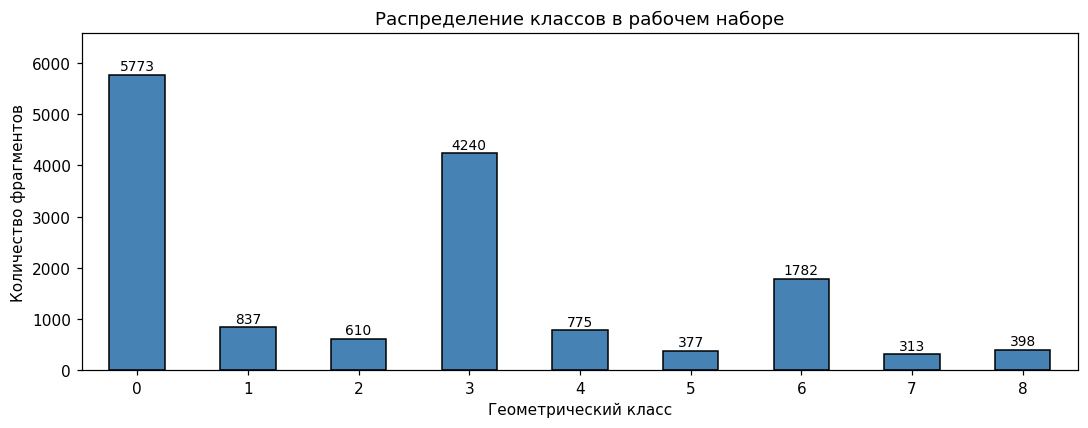

In [8]:
counts = df['label'].value_counts().sort_index().reindex(range(9), fill_value=0)
print(counts.to_string())
print(f'\nМакс/мин соотношение: {counts.max() / counts.min():.2f}x')

fig, ax = plt.subplots(figsize=(10, 4))
counts.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Распределение классов в рабочем наборе')
ax.set_xlabel('Геометрический класс')
ax.set_ylabel('Количество фрагментов')
ax.tick_params(axis='x', rotation=0)
for i, value in enumerate(counts):
    ax.text(i, value + counts.max() * 0.015, str(value), ha='center', fontsize=9)
ax.set_ylim(0, counts.max() * 1.14)
plt.tight_layout()
plt.show()

На общей диаграмме заметен дисбаланс: чаще всего встречаются классы 0 и 3.
Однако разные части набора сформированы по разным правилам. Чтобы понять
реальную нагрузку на будущий классификатор, нужно отдельно посмотреть
на распределения обучающей, валидационной и тестовой частей.

<h2 style="font-weight: normal;">Примеры каждого класса</h2>
Теперь выведу по одному примеру каждого класса: SEM, бинарную маску
и их наложение. Для воспроизводимости выбираю примеры с фиксированным
случайным состоянием из обучающей части с плотной разметкой.

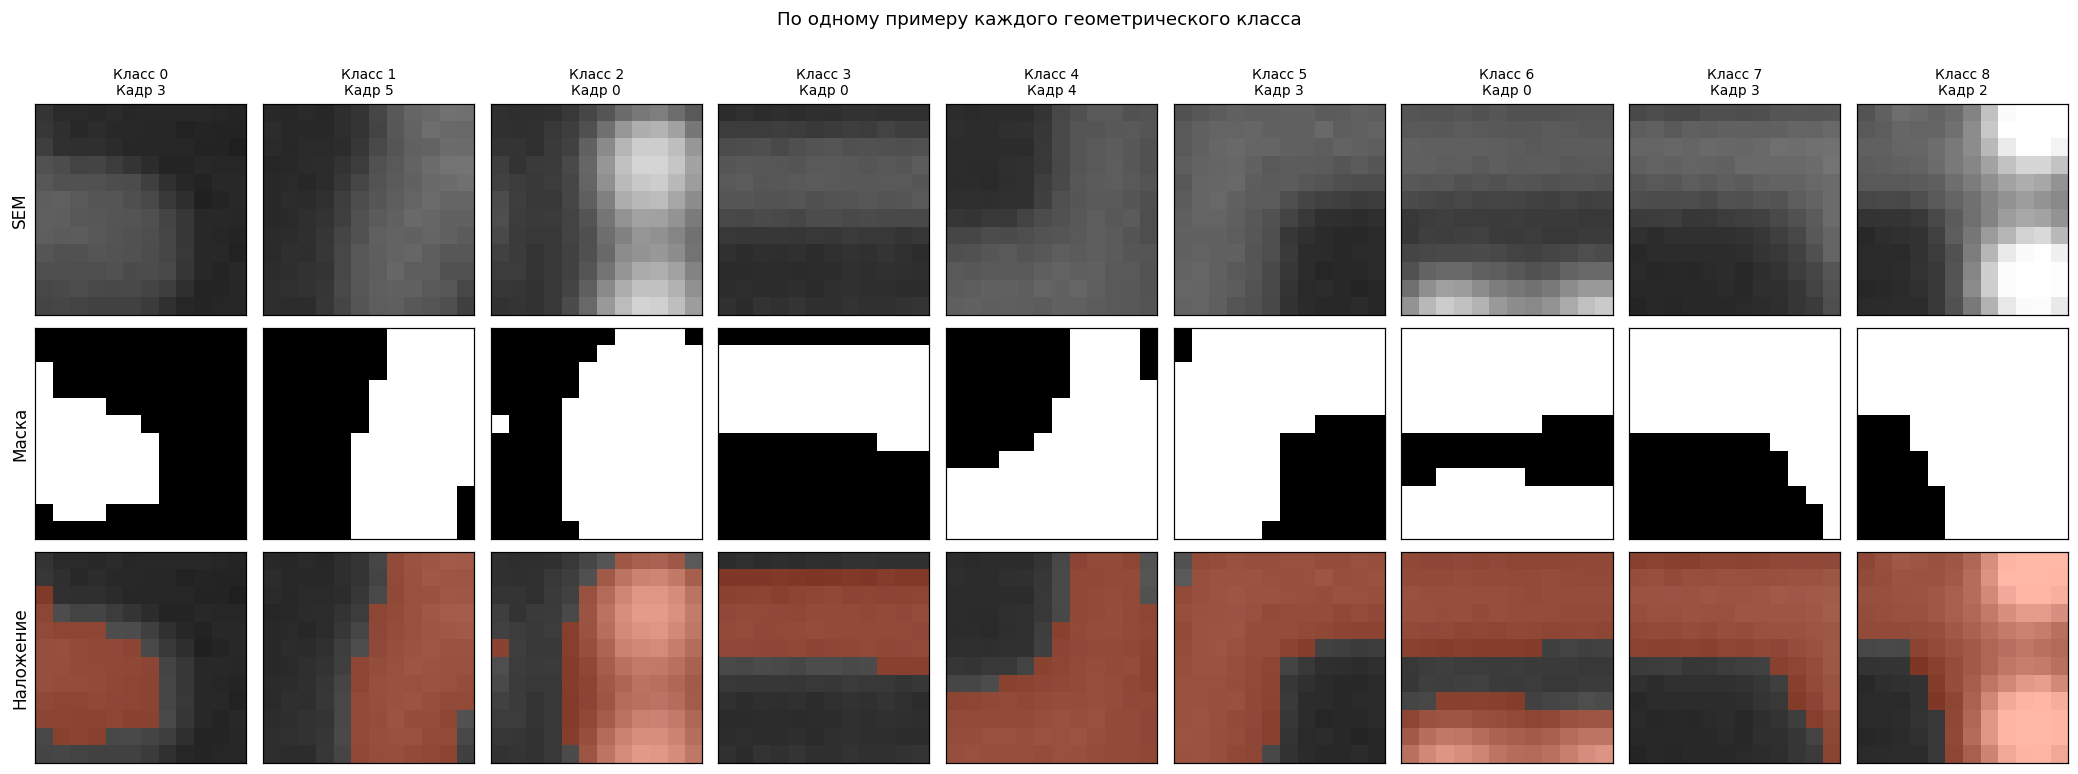

In [9]:
example_ids = [
    int(df[(df['label'] == c) & (df['role'] == 'dense')]
        .sample(n=1, random_state=RANDOM_STATE).index[0])
    for c in range(9)
]

fig, axes = plt.subplots(3, 9, figsize=(19, 7))
for col, i in enumerate(example_ids):
    axes[0, col].imshow(X[i], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes[0, col].set_title(f'Класс {df.loc[i, "label"]}\nКадр {df.loc[i, "frame"]}', fontsize=9)
    axes[1, col].imshow(Y[i], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes[2, col].imshow(X[i], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    overlay = np.zeros((*Y[i].shape, 4))
    overlay[Y[i].astype(bool)] = [1, 0.2, 0, 0.35]
    axes[2, col].imshow(overlay, interpolation='nearest')
for row, name in enumerate(['SEM', 'Маска', 'Наложение']):
    for col in range(9):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(name, fontsize=11)
plt.suptitle('По одному примеру каждого геометрического класса', y=1.01)
plt.tight_layout()
plt.show()

Примеры показывают, что близкая форма или доля металла ещё не определяет
класс: значение имеют перемычки и положение проводников относительно границ.

При повороте на 90° направления слева направо и сверху вниз меняются местами.
Если применять такую аугментацию при обучении, нужно соответствующим образом
преобразовывать и классовую метку.

---

<h1 style="font-weight: normal;">Проверка свойств изображений и масок</h1>
Далее посмотрю на яркость, заполненность масок и сложность геометрии.
Это поможет определить, какие признаки доступны будущей модели и какие
простые правила могут оказаться недостаточными.

Доля пикселей металла: 45.96%
Средняя яркость металла: 0.4577
Средняя яркость фона:    0.2053
Полностью пустых масок:  0
Полностью полных масок:  0
Постоянных SEM-фрагментов: 0


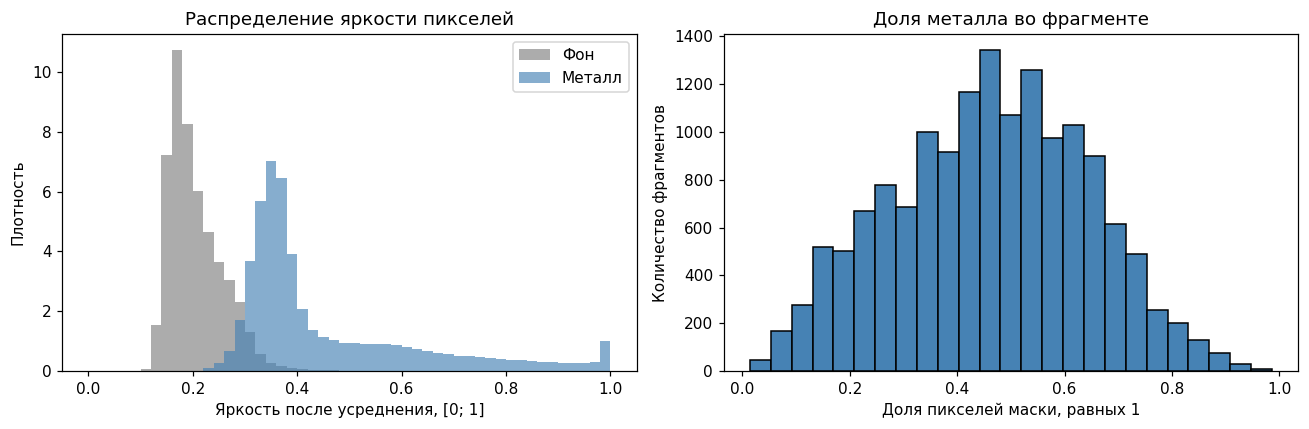

mean_intensity         std_intensity         metal_fraction        
                mean     std          mean     std           mean     std
role                                                                     
dense         0.3600  0.0948        0.1456  0.0768         0.5949  0.1626
weak          0.3513  0.0925        0.1436  0.0720         0.5761  0.1894
val           0.3476  0.0922        0.1516  0.0767         0.5497  0.1772
test          0.3172  0.0783        0.1418  0.0700         0.4442  0.1761

In [10]:
df['mean_intensity'] = X.mean((1, 2))
df['std_intensity'] = X.std((1, 2))
df['metal_fraction'] = Y.mean((1, 2))

print(f'Доля пикселей металла: {100 * Y.mean():.2f}%')
print(f'Средняя яркость металла: {X[Y == 1].mean():.4f}')
print(f'Средняя яркость фона:    {X[Y == 0].mean():.4f}')
print(f'Полностью пустых масок:  {(Y.sum((1, 2)) == 0).sum()}')
print(f'Полностью полных масок:  {(Y.sum((1, 2)) == 144).sum()}')
print(f'Постоянных SEM-фрагментов: {(X.std((1, 2)) == 0).sum()}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, 51)
axes[0].hist(X[Y == 0], bins=bins, density=True, alpha=0.65, label='Фон', color='gray')
axes[0].hist(X[Y == 1], bins=bins, density=True, alpha=0.65, label='Металл', color='steelblue')
axes[0].set_title('Распределение яркости пикселей')
axes[0].set_xlabel('Яркость после усреднения, [0; 1]')
axes[0].set_ylabel('Плотность')
axes[0].legend()
axes[1].hist(df['metal_fraction'], bins=25, color='steelblue', edgecolor='black')
axes[1].set_title('Доля металла во фрагменте')
axes[1].set_xlabel('Доля пикселей маски, равных 1')
axes[1].set_ylabel('Количество фрагментов')
plt.tight_layout()
plt.show()

display(df.groupby('role')[['mean_intensity', 'std_intensity', 'metal_fraction']]
        .agg(['mean', 'std']).reindex(['dense', 'weak', 'val', 'test']).round(4))

Металл в среднем ярче фона, но распределения яркости частично перекрываются.
Следовательно, один порог яркости не позволит безошибочно разделить
все пиксели этой подвыборки. Для восстановления геометрии потребуется
учитывать также пространственное окружение.

Пустых и полностью металлических масок в рабочем наборе нет, поскольку
они исключены при подготовке. Это свойство отбора, а не отсутствие таких
областей в исходных изображениях.

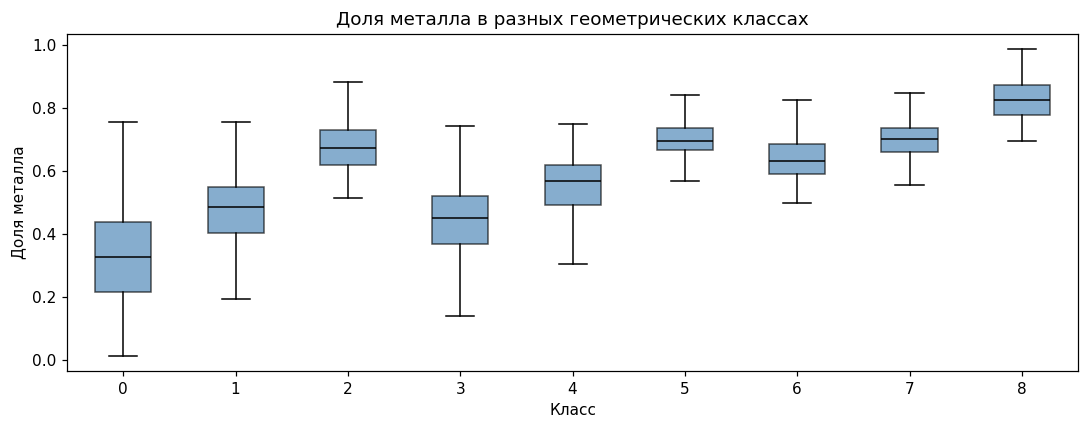

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([df.loc[df['label'] == c, 'metal_fraction'].to_numpy() for c in range(9)],
           tick_labels=[str(c) for c in range(9)], showfliers=False,
           patch_artist=True,
           boxprops={'facecolor': 'steelblue', 'alpha': 0.65},
           medianprops={'color': 'black'})
ax.set_title('Доля металла в разных геометрических классах')
ax.set_xlabel('Класс')
ax.set_ylabel('Доля металла')
plt.tight_layout()
plt.show()

Распределения доли металла у разных классов перекрываются. Значит,
заполненности фрагмента недостаточно для однозначного определения класса.

Дополнительно посчитаю связные компоненты и наличие пути между границами.
Использую четырёхсвязное соседство, соответствующее геометрическому правилу
классификации. Так можно проверить согласованность меток с наличием соединений.

Несогласованность наличия пути и сохранённого класса: 0


,metal_fraction,components,mean_intensity,std_intensity
count,15105.0000,15105.0000,15105.0000,15105.0000
mean,0.4596,1.3633,0.3213,0.1424
std,0.1819,0.5050,0.0810,0.0705
min,0.0139,1.0000,0.1585,0.0311
25%,0.3264,1.0000,0.2620,0.0788
50%,0.4653,1.0000,0.3034,0.1195
75%,0.5903,2.0000,0.3758,0.2039
max,0.9861,3.0000,0.5997,0.3428


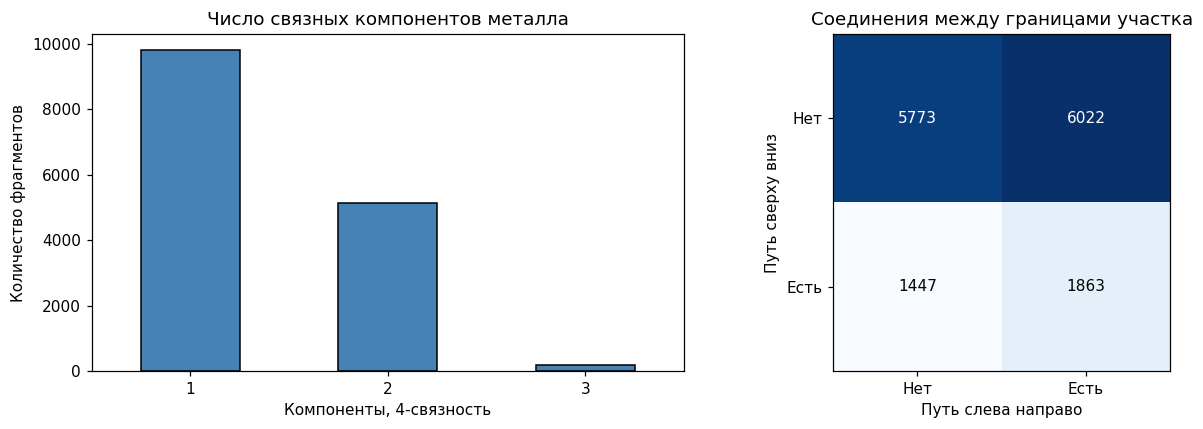

In [12]:
structure = ndi.generate_binary_structure(2, 1)
components, path_lr, path_tb = [], [], []
for mask in Y:
    labelled, number = ndi.label(mask, structure=structure)
    components.append(number)
    lr = set(labelled[:, 0]) & set(labelled[:, -1]) - {0}
    tb = set(labelled[0, :]) & set(labelled[-1, :]) - {0}
    path_lr.append(bool(lr))
    path_tb.append(bool(tb))

df['components'] = components
df['path_lr'] = path_lr
df['path_tb'] = path_tb

# Независимая проверка только наличия пути, без пересчёта градаций отклика.
path_mismatch = ((df['path_lr'] != (df['label'] // 3 > 0)) |
                 (df['path_tb'] != (df['label'] % 3 > 0))).sum()
print(f'Несогласованность наличия пути и сохранённого класса: {path_mismatch}')
assert path_mismatch == 0
display(df[['metal_fraction', 'components', 'mean_intensity', 'std_intensity']]
        .describe().round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
component_counts = df['components'].value_counts().sort_index()
component_counts.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Число связных компонентов металла')
axes[0].set_xlabel('Компоненты, 4-связность')
axes[0].set_ylabel('Количество фрагментов')
axes[0].tick_params(axis='x', rotation=0)
connectivity = pd.crosstab(df['path_tb'], df['path_lr']).reindex(
    index=[False, True], columns=[False, True], fill_value=0)
axes[1].imshow(connectivity, cmap='Blues')
for (r, c), value in np.ndenumerate(connectivity.to_numpy()):
    axes[1].text(c, r, str(value), ha='center', va='center',
                 color='white' if value > connectivity.to_numpy().max() * .5 else 'black')
axes[1].set_xticks([0, 1], ['Нет', 'Есть'])
axes[1].set_yticks([0, 1], ['Нет', 'Есть'])
axes[1].set_xlabel('Путь слева направо')
axes[1].set_ylabel('Путь сверху вниз')
axes[1].set_title('Соединения между границами участка')
plt.tight_layout()
plt.show()

---

<h1 style="font-weight: normal;">Разбиение данных и повторы</h1>
До обучения важно проверить разделение данных. Единицей разбиения выбираю
исходный кадр, поскольку соседние фрагменты одного изображения могут
перекрываться. Случайное деление всех фрагментов без учёта кадра создаст
риск попадания близких областей в разные части набора.

Предусматриваются четыре назначения примеров:

- `dense` — обучающие изображения с плотной маской и классом;
- `weak` — обучающие изображения, для которых при оптимизации будет
  использоваться класс без пиксельного надзора;
- `val` — выбор настроек модели и порога;
- `test` — оценка итогового качества.

В плотной обучающей части доступно 54 маски. Это позволит отдельно
рассматривать обучение при ограниченном объёме плотной разметки.

Маски `weak` также сохранены: из них получены геометрические классы.
Ограничение относится к тому, какая информация будет передаваться модели
при обучении. Такой набор позволяет моделировать дефицит плотного надзора,
но сам по себе не показывает, что слабые метки дешевле получить на производстве.

,Фрагментов,Кадров,Номера кадров
role,,,
dense,54,6,"[0, 1, 2, 3, 4, 5]"
weak,1152,6,"[0, 1, 2, 3, 4, 5]"
val,695,2,"[6, 7]"
test,13204,8,"[41, 47, 92, 120, 217, 245, 263, 287]"


label,0,1,2,3,4,5,6,7,8
role,,,,,,,,,
dense,6,6,6,6,6,6,6,6,6
weak,128,128,128,128,128,128,128,128,128
val,96,96,91,96,96,48,96,31,45
test,5543,607,385,4010,545,195,1552,148,219


dense: макс/мин = 1.00x
weak : макс/мин = 1.00x
val  : макс/мин = 3.10x
test : макс/мин = 37.45x


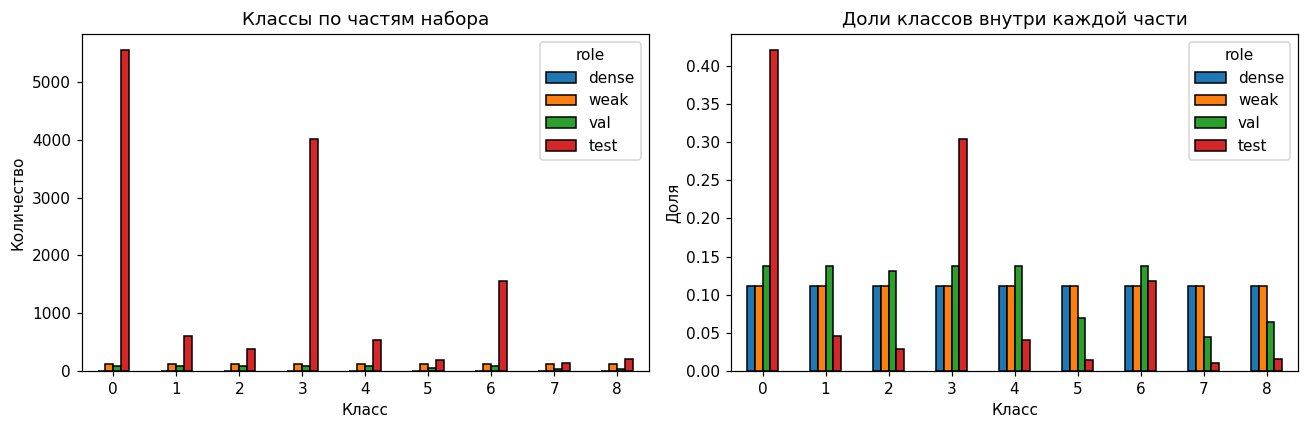

In [13]:
role_order = ['dense', 'weak', 'val', 'test']
role_counts = pd.crosstab(df['role'], df['label']).reindex(
    index=role_order, columns=range(9), fill_value=0)
role_summary = pd.DataFrame({
    'Фрагментов': df.groupby('role').size(),
    'Кадров': df.groupby('role')['frame'].nunique(),
    'Номера кадров': df.groupby('role')['frame'].apply(lambda s: sorted(s.unique().tolist()))
}).reindex(role_order)
display(role_summary)
display(role_counts)

for role in role_order:
    values = role_counts.loc[role]
    print(f'{role:5s}: макс/мин = {values.max() / values.min():.2f}x')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
role_counts.T.plot(kind='bar', ax=axes[0], edgecolor='black')
axes[0].set_title('Классы по частям набора')
axes[0].set_xlabel('Класс')
axes[0].set_ylabel('Количество')
axes[0].tick_params(axis='x', rotation=0)
role_counts.div(role_counts.sum(axis=1), axis=0).T.plot(kind='bar', ax=axes[1], edgecolor='black')
axes[1].set_title('Доли классов внутри каждой части')
axes[1].set_xlabel('Класс')
axes[1].set_ylabel('Доля')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

Общие номера кадров train/val: []
Общие номера кадров train/test: []
Общие номера кадров val/test: []


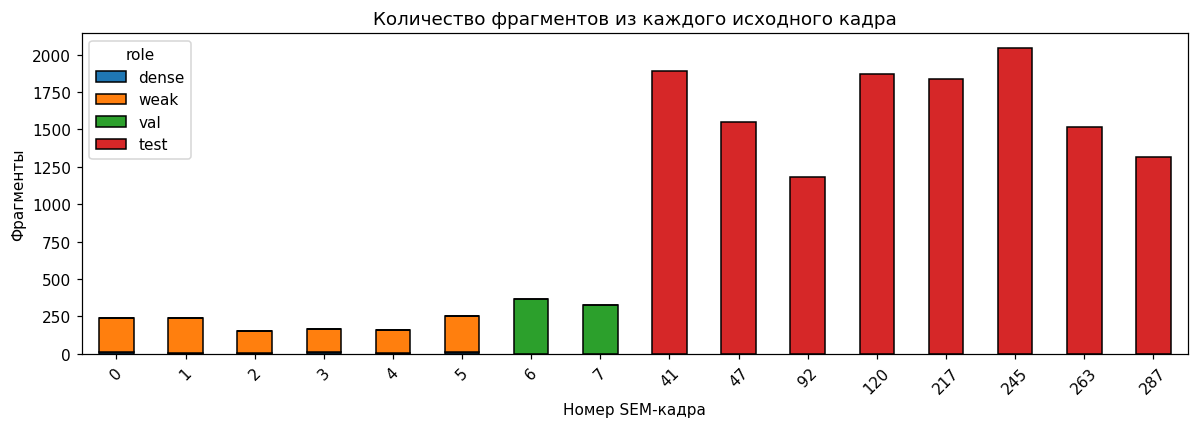

In [14]:
frame_sets = {split: set(df.loc[df['split'] == split, 'frame'])
              for split in ['train', 'val', 'test']}
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    common = frame_sets[a] & frame_sets[b]
    print(f'Общие номера кадров {a}/{b}: {sorted(common)}')
    assert not common

frame_counts = pd.crosstab(df['frame'], df['role']).reindex(columns=role_order, fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4))
frame_counts.plot(kind='bar', stacked=True, ax=ax, edgecolor='black')
ax.set_title('Количество фрагментов из каждого исходного кадра')
ax.set_xlabel('Номер SEM-кадра')
ax.set_ylabel('Фрагменты')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Обучающие примеры сбалансированы по классам за счёт отбора. В тестовой части
дисбаланс значительно сильнее, а число фрагментов зависит от кадра.
Поэтому при оценке классификации следует использовать Macro-F1 и показывать
результаты по отдельным классам: общая доля правильных ответов может скрыть
ошибки редких состояний.

Общих номеров кадров между TRAIN, VAL и TEST нет. При этом все кадры относятся
к одной микросхеме, а поля съёмки могут перекрываться примерно на 10%.
Разделение по номерам кадров не гарантирует пространственную независимость
и не заменяет проверку на другом изделии.

In [15]:
def canonical_keys(images, binary=False):
    # Восемь симметрий квадрата: четыре поворота и их отражения.
    views = [np.rot90(images, k, axes=(1, 2)) for k in range(4)]
    views += [view[:, :, ::-1] for view in views]
    if binary:
        rows = [np.packbits(view.reshape(len(view), -1), axis=1) for view in views]
    else:
        rows = [view.astype('<u2').reshape(len(view), -1) for view in views]
    return [min(row[i].tobytes() for row in rows) for i in range(len(images))]

raw_sums = np.rint(X * (16 * 255)).astype(np.uint16)
mask_d4 = canonical_keys(Y, binary=True)
image_d4 = canonical_keys(raw_sums)
exact_images = [image.tobytes() for image in X]
exact_masks = [np.packbits(mask).tobytes() for mask in Y]

duplicate_counts = {
    'SEM, точное совпадение': len(X) - len(set(exact_images)),
    'Маска, точное совпадение': len(Y) - len(set(exact_masks)),
    'SEM, с учётом поворотов и отражений': len(X) - len(set(image_d4)),
    'Маска, с учётом поворотов и отражений': len(Y) - len(set(mask_d4))
}
display(pd.Series(duplicate_counts, name='Повторных записей').to_frame())

assert [key.hex() for key in mask_d4] == df['canonical_D4'].tolist()
assert [hashlib.sha256(key).hexdigest() for key in image_d4] == df['raw_D4_sha256'].tolist()
assert all(value == 0 for value in duplicate_counts.values())

overlap_rows = []
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    a_ids = np.flatnonzero(df['split'].to_numpy() == a)
    b_ids = np.flatnonzero(df['split'].to_numpy() == b)
    overlap_rows.append({
        'Пара': f'{a}/{b}',
        'Общих SEM-мотивов D4': len({image_d4[i] for i in a_ids} & {image_d4[i] for i in b_ids}),
        'Общих масок D4': len({mask_d4[i] for i in a_ids} & {mask_d4[i] for i in b_ids})
    })
display(pd.DataFrame(overlap_rows))

,Повторных записей
"SEM, точное совпадение",0
"Маска, точное совпадение",0
"SEM, с учётом поворотов и отражений",0
"Маска, с учётом поворотов и отражений",0


,Пара,Общих SEM-мотивов D4,Общих масок D4
0,train/val,0,0
1,train/test,0,0
2,val/test,0,0


Точных повторов изображений и масок не найдено, в том числе после поворотов
и отражений. Ключи, рассчитанные из массивов, совпадают с таблицей описания.
При этом отсутствие точных повторов ещё не исключает очень похожие участки.

Шаг вырезания вдвое меньше ширины фрагмента, поэтому соседние участки внутри
кадра могут перекрываться. Проверю такие пары между плотной и слабой
обучающими частями и посмотрю на расположение фрагментов в кадрах.

Плотных TRAIN-фрагментов с перекрывающимся weak-фрагментом: 24 из 54


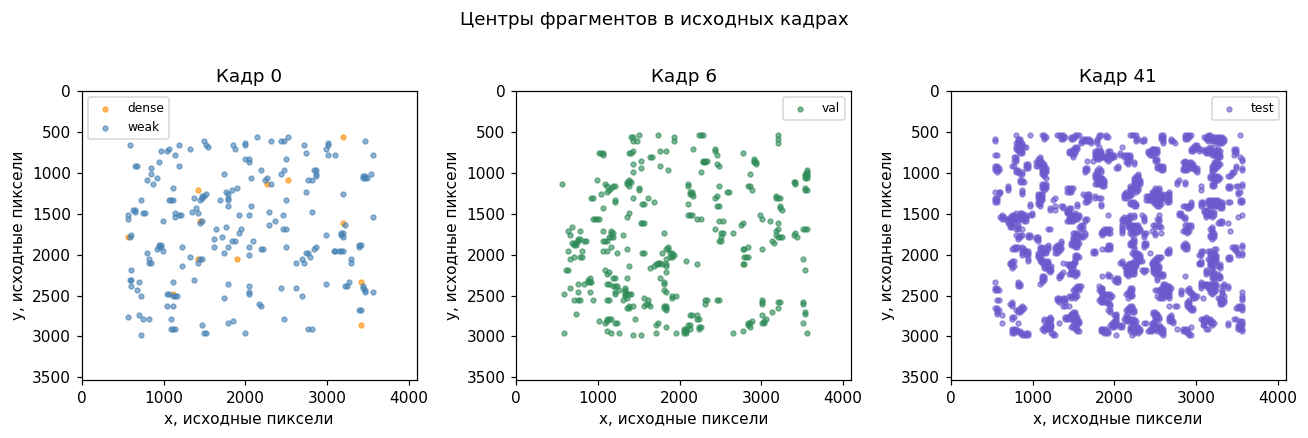

In [16]:
overlapping_dense_ids = set()
for frame in sorted(frame_sets['train']):
    dense_part = df[(df['frame'] == frame) & (df['role'] == 'dense')]
    weak_part = df[(df['frame'] == frame) & (df['role'] == 'weak')]
    if len(dense_part) and len(weak_part):
        tree = cKDTree(weak_part[['x', 'y']].to_numpy())
        neighbours = tree.query_ball_point(dense_part[['x', 'y']].to_numpy(), r=47.99, p=np.inf)
        overlapping_dense_ids.update(dense_part.index[j] for j, values in enumerate(neighbours) if len(values))
print(f'Плотных TRAIN-фрагментов с перекрывающимся weak-фрагментом: '
      f'{len(overlapping_dense_ids)} из {(df["role"] == "dense").sum()}')

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, frame in zip(axes, [0, 6, 41]):
    part = df[df['frame'] == frame]
    for role, color in [('dense', 'darkorange'), ('weak', 'steelblue'), ('val', 'seagreen'), ('test', 'slateblue')]:
        selected = part[part['role'] == role]
        if len(selected):
            ax.scatter(selected['x'] + 24, selected['y'] + 24,
                       s=10, alpha=0.6, label=role, color=color)
    ax.set_title(f'Кадр {frame}')
    ax.set_xlim(0, 4096)
    ax.set_ylim(3536, 0)
    ax.set_aspect('equal')
    ax.set_xlabel('x, исходные пиксели')
    ax.set_ylabel('y, исходные пиксели')
    ax.legend(fontsize=8)
plt.suptitle('Центры фрагментов в исходных кадрах')
plt.tight_layout()
plt.show()

Перекрытие внутри обучающей части делает фрагменты зависимыми. Поэтому
при последующей оценке неопределённости качества нужно учитывать
группировку по исходным кадрам, а не считать все участки независимыми.

<h2 style="font-weight: normal;">Согласованность файлов набора</h2>
Проверю, что отдельный файл TRAIN/VAL содержит те же примеры, что и общий
архив. Для быстрых оценок также предусмотрена подвыборка EVAL.
Она должна входить в TEST и сохранять соответствие исходным записям.
EVAL не следует прибавлять к TEST как дополнительный набор наблюдений.

In [17]:
with np.load(DATA_DIR / 'TRAIN_VAL.npz', allow_pickle=False) as archive:
    trainval = {key: archive[key].copy() for key in archive.files}
trainval_ids = np.flatnonzero(arrays['role'] != 'test')
assert all(np.array_equal(trainval[key], arrays[key][trainval_ids]) for key in trainval)

eval_index = json.loads((DATA_DIR / 'EVAL_INDEX.json').read_text())
eval_ids = np.asarray(eval_index['global_DATA_indices'], dtype=int)
with np.load(DATA_DIR / 'EVAL.npz', allow_pickle=False) as archive:
    assert all(np.array_equal(archive[key], arrays[key][eval_ids]) for key in archive.files)
assert (arrays['role'][eval_ids] == 'test').all()

print(f'TRAIN/VAL: {len(trainval_ids):,} объектов; все массивы совпадают.')
print(f'EVAL: {len(eval_ids):,} объектов; все входят в TEST, новых кадров не добавляют.')
print(f'Фрагментов EVAL на кадр: {pd.Series(arrays["frame"][eval_ids]).value_counts().sort_index().to_dict()}')

TRAIN/VAL: 1,901 объектов; все массивы совпадают.
EVAL: 2,048 объектов; все входят в TEST, новых кадров не добавляют.
Фрагментов EVAL на кадр: {41: 256, 47: 256, 92: 256, 120: 256, 217: 256, 245: 256, 263: 256, 287: 256}


---

<h1 style="font-weight: normal;">Выводы по датасету</h1>
1. Рабочая подвыборка содержит 15 105 фрагментов из 16 кадров одного ИС.
   Для каждого фрагмента доступны SEM и маска металлизации. Исходный набор M2
   включает 321 кадр и соответствующие SVG-разметки.

2. На основе масок можно сформировать девять геометрических состояний.
   Они описывают соединения и градации отклика условной решётки,
   но не являются экспертными категориями производственных дефектов.

3. Пропусков, неконечных значений и точных повторов не обнаружено.
   Соседние фрагменты могут перекрываться, поэтому разбиение и оценку
   неопределённости нужно проводить с учётом исходных кадров.

4. Яркость и доля металла полезны, но не позволяют однозначно восстановить
   геометрию и класс. При построении модели необходимо учитывать
   пространственное окружение и соединения между участками металла.

5. Уменьшение до $12\times12$ упрощает обработку, но меняет представление
   тонких границ. Поэтому при оценке сегментации следует проверять
   не только IoU/Dice, но и сохранение соединений.
   
6. Дисбаланс тестовой части требует Macro-F1 и анализа каждого класса.
   Поскольку набор относится к одной микросхеме, перенос на другие изделия
   необходимо будет проверять отдельно.